# Project Objective:
The objective of this project is to build and evaluate machine learning models for predicting a quantitative measure of diabetes disease progression one year after the baseline measurement. The project uses the `load_diabetes` dataset available in the `scikit-learn` library.
Unlike a classification problem where the objective is to predict whether a patient belongs to a particular class, this problem is a regression problem. The target variable is continuous and represents the quantitative measure of disease progression. Therefore,
the central modelling objective is to learn a function

$$f : \mathbb{R}^{10} \rightarrow \mathbb{R}$$

such that
$$\hat{y} = f(x)$$
provides an accurate estimate of the disease-progression measure y from the patient’s baseline characteristics x.

# 1. Load Dataset

In [145]:
from sklearn.datasets import load_diabetes
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

In [146]:
diabetes = load_diabetes(as_frame=True, scaled=False) # Load the diabetes dataset as a DataFrame without scaling
diabetes_df = diabetes.frame
print(diabetes_df.shape)
print(diabetes_df.info(verbose=True))
print(diabetes_df.describe(include='all'))
print(diabetes_df.head(10))
print("Nulls and missing values")
print(diabetes_df.isnull().sum())
print("No.of Duplicates:"+str(diabetes_df.duplicated().sum()))


(442, 11)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 442 entries, 0 to 441
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   age     442 non-null    float64
 1   sex     442 non-null    float64
 2   bmi     442 non-null    float64
 3   bp      442 non-null    float64
 4   s1      442 non-null    float64
 5   s2      442 non-null    float64
 6   s3      442 non-null    float64
 7   s4      442 non-null    float64
 8   s5      442 non-null    float64
 9   s6      442 non-null    float64
 10  target  442 non-null    float64
dtypes: float64(11)
memory usage: 38.1 KB
None
              age         sex         bmi          bp          s1          s2  \
count  442.000000  442.000000  442.000000  442.000000  442.000000  442.000000   
mean    48.518100    1.468326   26.375792   94.647014  189.140271  115.439140   
std     13.109028    0.499561    4.418122   13.831283   34.608052   30.413081   
min     19.000000    1.000000   1

# 2.EDA

- Plot **histograms** with KDE for all features to understand their distributions and detect skewness
- Perform **Pair plot** to understand correlation among the variables - visually
- Plot **Correlation heat map** - to get the correlation values for the varaibles. This will be more helpful than pair plot
- **Box Plots** - to check if there are any potential outliers in the data set

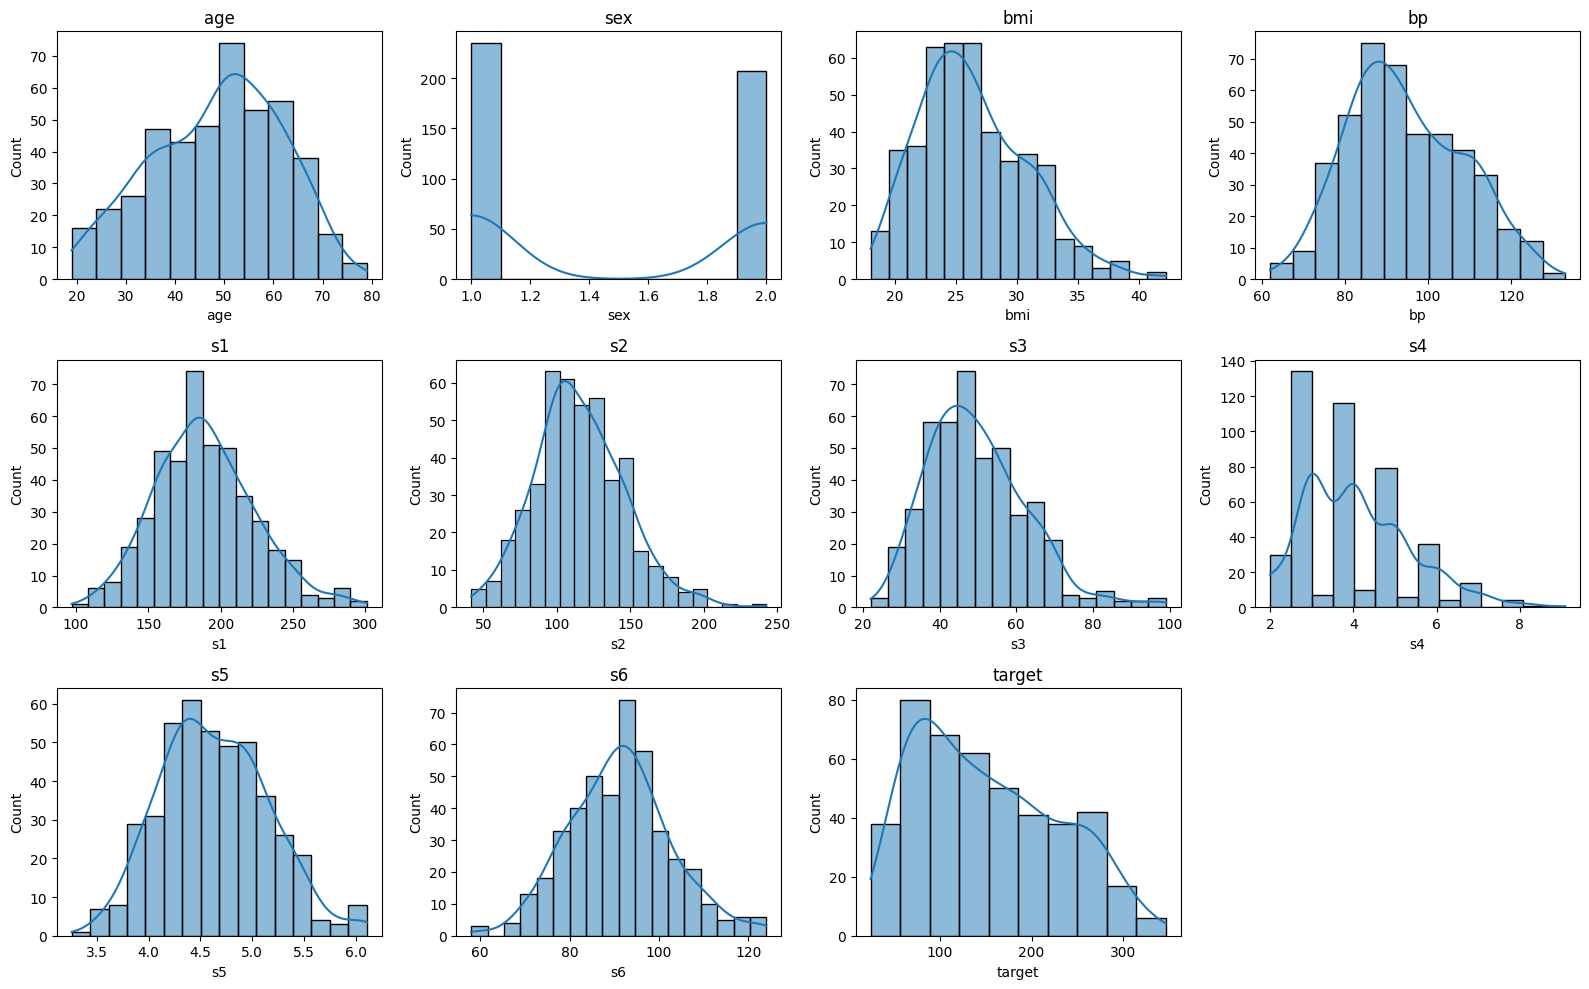

In [147]:
# Generate Hist plots for all features with KDE
fig, axes = plt.subplots(3, 4, figsize=(16, 10))
for ax, col in zip(axes.flatten(), diabetes_df.columns):
    sns.histplot(diabetes_df[col], kde=True, ax=ax)
    ax.set_title(col)
# hide unused subplots
for ax in axes.flatten()[len(diabetes_df.columns):]:
    ax.set_visible(False)
plt.tight_layout()
plt.savefig('../charts/histograms.png')
plt.show()

#### Histogram Analysis:
- Target variable is right skewed
- `s4` appears to be in some discrete range rather than continuous like other features

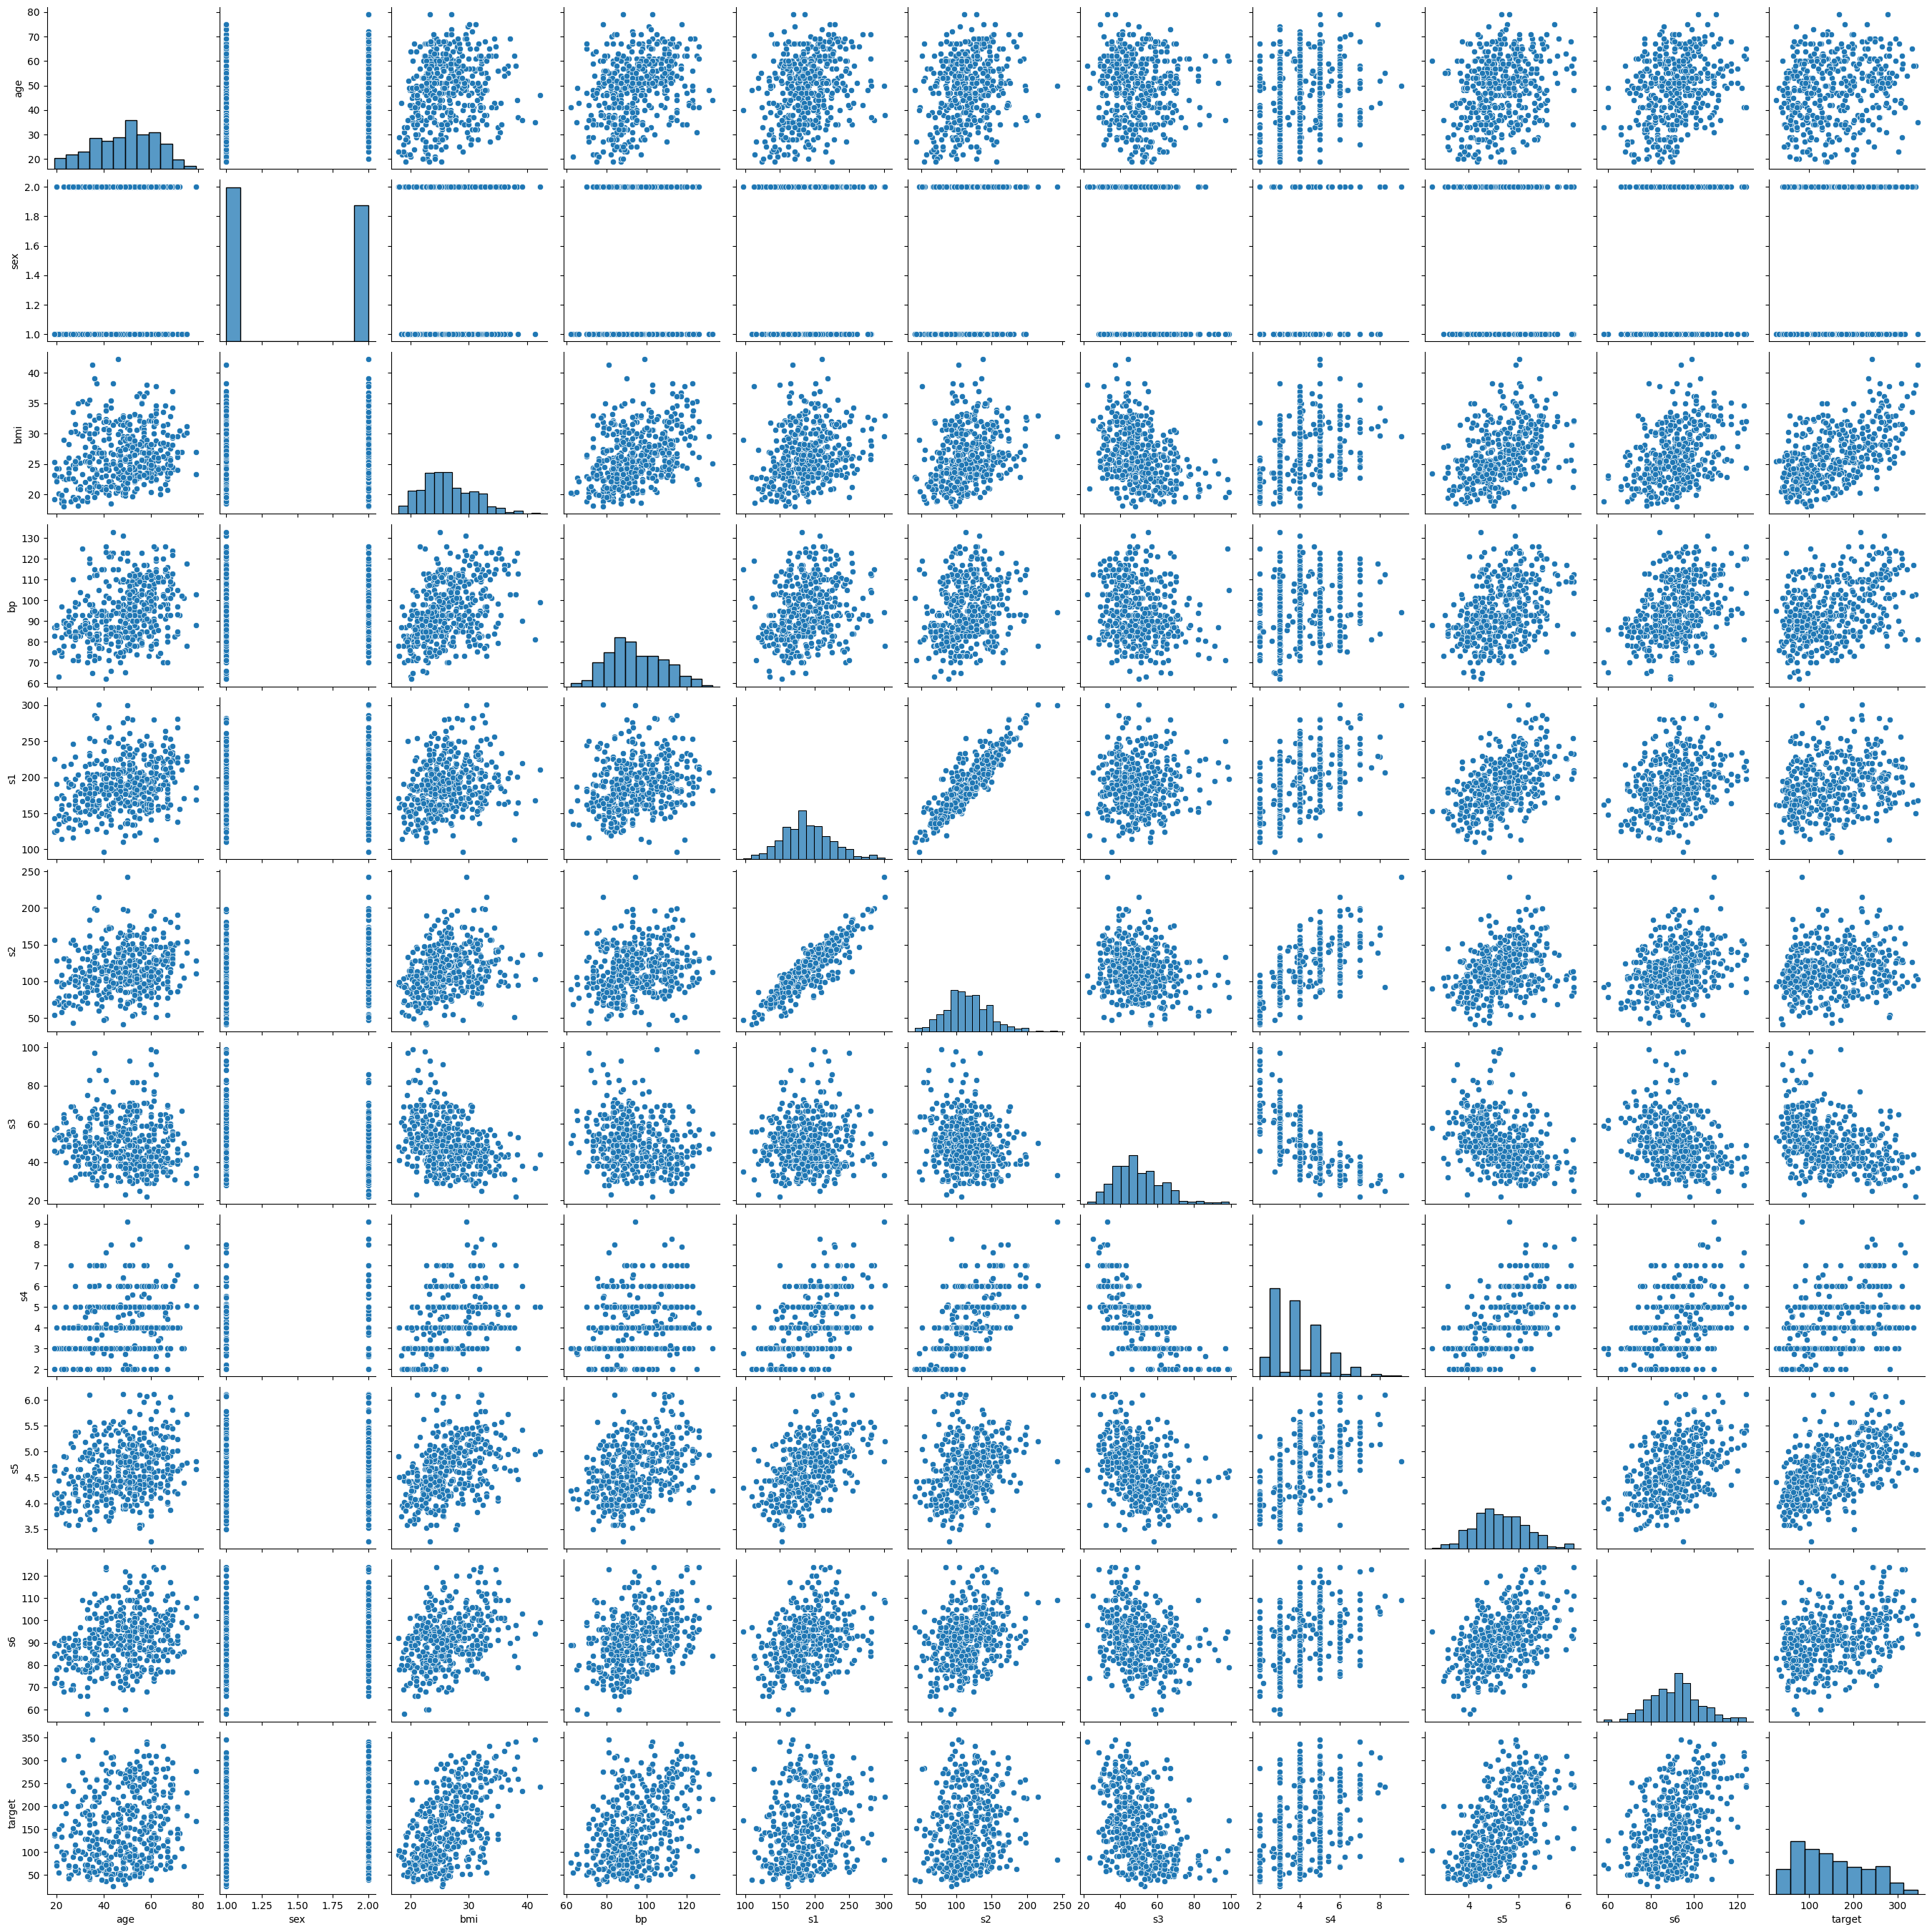

In [148]:
sns.pairplot(diabetes_df)
plt.savefig('../charts/pairplot.png')
plt.show()

#### Pair plot analysis
- `bmi`, `bp`, `s4`, and `s5` show visible positive linear trends with `target`, consistent with their higher correlation values.
- `s1` and `s2` cluster tightly along a diagonal, confirming strong collinearity between them.
- `sex` is binary-coded (1/2), so its scatterplots form two bands rather than a continuous trend.
- Diagonal histograms show most features are roughly normal, while `target` is right-skewed.

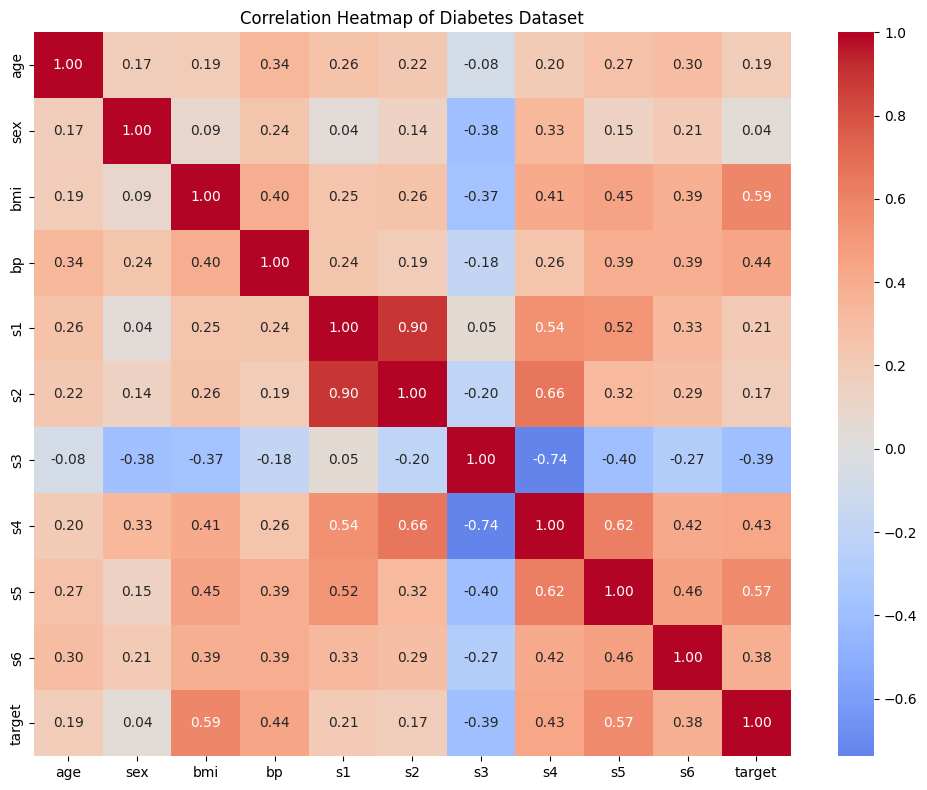

Correlation with target variable:
target    1.000000
bmi       0.586450
s5        0.565883
bp        0.441482
s4        0.430453
s6        0.382483
s1        0.212022
age       0.187889
s2        0.174054
sex       0.043062
s3       -0.394789
Name: target, dtype: float64


In [149]:
# Correlation analysis between features and target
corr = diabetes_df.corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation Heatmap of Diabetes Dataset')
plt.tight_layout()
plt.savefig('../charts/correlation_heatmap.png')
plt.show()

# Print correlations with target, sorted
print("Correlation with target variable:")
print(corr['target'].sort_values(ascending=False))

#### Correlation Heatmap Analysis:
- `bmi` (0.59) and `s5` (0.57) are most correlated with `target`, followed by `bp` (0.44) and `s4` (0.43).
- `s1` and `s2` are highly collinear (0.90), and `s3`/`s4` are strongly negatively correlated (-0.74) — a multicollinearity risk for linear regression.
- `sex` has almost no linear correlation with `target` (0.04).

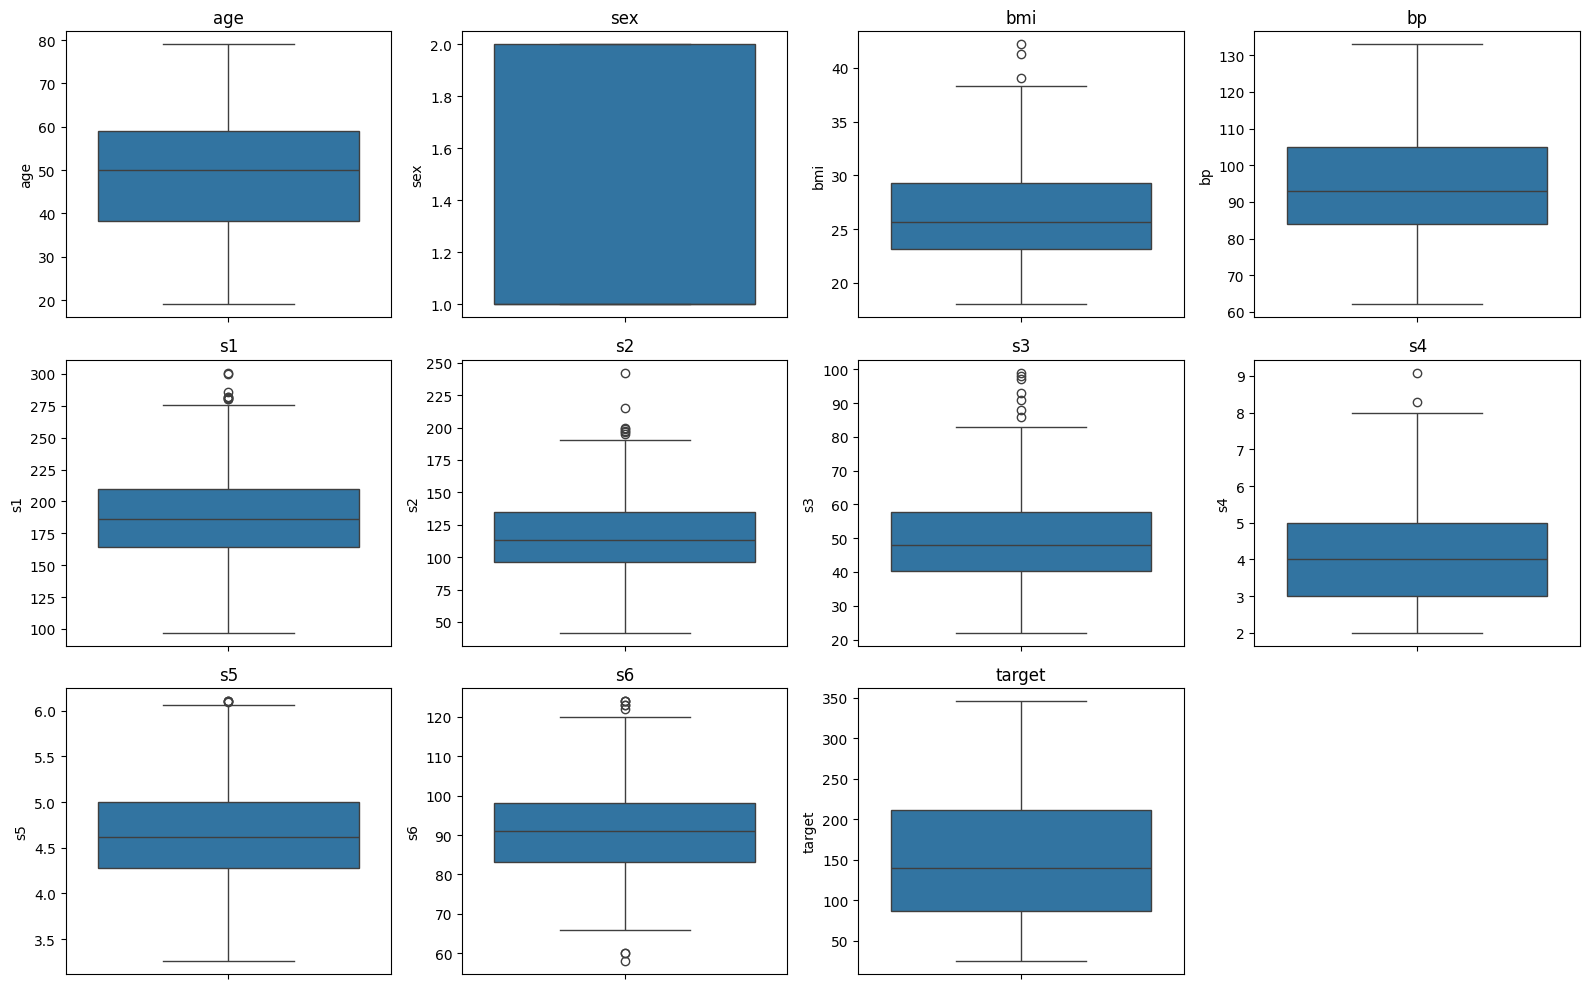

In [150]:
fig, axes = plt.subplots(3, 4, figsize=(16, 10))
for ax, col in zip(axes.flatten(), diabetes_df.columns):
    sns.boxplot(y=diabetes_df[col], ax=ax)
    ax.set_title(col)
# hide unused subplots since columns don't fill the grid
for ax in axes.flatten()[len(diabetes_df.columns):]:
    ax.set_visible(False)
plt.tight_layout()
plt.savefig('../charts/boxplots.png')
plt.show()

#### Box plots Analysis:
- `bmi`, `s1`, `s2`, `s3`, and `s4` show values beyond the upper whisker, indicating potential outliers.
- `age`, `bp`, and `target` show fairly symmetric spreads with no notable outliers.
- `sex` is binary, so a boxplot isn't meaningful for it.

Because of the smaller dataset, rather than removing/imputing the outliers, let's keep them as such and proceed further

# 3a. Model Evaluation

This section establishes baseline linear models before exploring non-linear feature engineering and models.

**Steps performed:**
1. Split the diabetes dataset into training (80%) and testing (20%) sets.
2. Fit an unscaled OLS model via `statsmodels` as an interpretability baseline, reviewing coefficients, p-values, and confidence intervals.
3. Ran `GridSearchCV` with `KFold` cross-validation to tune the regularization strength (`alpha`) for Ridge and Lasso using a scaled pipeline.
4. Trained and compared OLS, Ridge, Lasso, and their tuned (best-alpha) variants on the test set using MSE, RMSE, MAE, and R².
5. Extracted and compared standardized coefficients across models to assess feature importance and the effect of regularization.
6. Visualized results: test R² bar chart across models, actual vs. predicted scatter plots with residuals, and standardized coefficient comparisons — to evaluate performance, diagnose errors, and understand regularization's impact on multicollinearity.

In [151]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.model_selection import train_test_split, GridSearchCV,KFold
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error,root_mean_squared_error
import statsmodels.api as sm
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
import numpy as np

#### Split the data to train and test

In [152]:
# Split the data into training and testing sets
X = diabetes_df.drop(columns=['target'])
y = diabetes_df['target']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

#### OLS as baseline
- OLS achieves R² ≈ 0.453 on the test set, with RMSE ≈ 53.85 and MAE ≈ 42.79, setting the baseline performance to beat.
- The `statsmodels` summary provides p-values and confidence intervals for each coefficient, useful for identifying statistically significant predictors (e.g., `bmi`, `bp`, `s1`, `s2`, `s5` tend to be significant, while `age` and `s6` are not).
- This unscaled OLS model serves purely as an interpretability/reference baseline; scaled versions (Ridge/Lasso) are used later for fair coefficient comparison and regularization.

In [153]:
# use OLS without scaling as a baseline model
X_train_ols = sm.add_constant(X_train)
X_test_ols = sm.add_constant(X_test)
ols_model = sm.OLS(y_train, X_train_ols).fit()
y_pred_ols = ols_model.predict(X_test_ols)

mse_ols = mean_squared_error(y_test, y_pred_ols)
rmse_ols = root_mean_squared_error(y_test, y_pred_ols)
mae_ols = mean_absolute_error(y_test, y_pred_ols)
r2_ols = r2_score(y_test, y_pred_ols)

print(f"OLS Mean Squared Error: {mse_ols:.6f}")
print(f"OLS Root Mean Squared Error: {rmse_ols:.6f}")
print(f"OLS Mean Absolute Error: {mae_ols:.6f}")
print(f"OLS R^2 Score: {r2_ols:.6f}")

print(ols_model.summary())
# Full statsmodels summary: coefficients, p-values, confidence intervals, etc.

OLS Mean Squared Error: 2900.193628
OLS Root Mean Squared Error: 53.853446
OLS Mean Absolute Error: 42.794095
OLS R^2 Score: 0.452603
                            OLS Regression Results                            
Dep. Variable:                 target   R-squared:                       0.528
Model:                            OLS   Adj. R-squared:                  0.514
Method:                 Least Squares   F-statistic:                     38.25
Date:                Mon, 19 Oct 2026   Prob (F-statistic):           5.41e-50
Time:                        15:55:49   Log-Likelihood:                -1906.1
No. Observations:                 353   AIC:                             3834.
Df Residuals:                     342   BIC:                             3877.
Df Model:                          10                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.97

#### Perform Cross Validation on Ridge and Lasso to find the good hyper parameter - alpha
- Best Ridge alpha ≈ 0.869 with CV R² ≈ 0.481, close to default Ridge performance.
- Best Lasso alpha ≈ 0.596 with CV R² ≈ 0.481, indicating mild regularization works best here.
- Both tuned models yield similar CV performance to OLS, suggesting limited multicollinearity impact on this dataset at the linear level.

In [154]:
# Perform Grid Search CV for Ridge and Lasso models - Create a method with parameterized hyperparameters and models
def perform_grid_search(model, alphas):
    param_grid = {'model__alpha': alphas}
    cv=KFold(n_splits=5, shuffle=True, random_state=42)
    pipe = Pipeline([
        ('scaler', StandardScaler()),
        ('model', model)
    ])
    grid_search = GridSearchCV(pipe, param_grid, cv=cv, scoring='r2')
    grid_search.fit(X_train, y_train)
    return grid_search

ridge_grid = perform_grid_search(Ridge(), np.logspace(-3, 3, 50))
lasso_grid = perform_grid_search(Lasso(max_iter=10000), np.logspace(-3, 1, 50))

for name, g in [("Ridge", ridge_grid), ("Lasso", lasso_grid)]:
    print(name, "best alpha:", f"{g.best_params_['model__alpha']:.6f}",
          f"| CV R^2: {g.best_score_:.6f}")


Ridge best alpha: 0.868511 | CV R^2: 0.480785
Lasso best alpha: 0.596362 | CV R^2: 0.481298


In [155]:
results = []
coefs = {}
intercepts = {}

# Create Pipeline for Standard Scaling - can be used for any model later
# Loop through different models Linear Regression, Ridge, Lasso with the pipeline

models = {
    'OLS': LinearRegression(), # using LinearRegression to fit an ordinary least squares model (baseline model)
    'Ridge': Ridge(),
    'Lasso': Lasso(),
    'Ridge with tuned alpha': Ridge(alpha=ridge_grid.best_params_['model__alpha']),
    'Lasso with tuned alpha': Lasso(alpha=lasso_grid.best_params_['model__alpha'],max_iter=10000)
}

for model_name, model in models.items():
    pipe = Pipeline([('scaler', StandardScaler()), ('model', model)])
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)

    results.append({
        'Model': model_name,
        'MSE':  mean_squared_error(y_test, y_pred),
        'RMSE': root_mean_squared_error(y_test, y_pred),
        'MAE':  mean_absolute_error(y_test, y_pred),
        'R2':   r2_score(y_test, y_pred),
    })

    fitted_model = pipe.named_steps['model']
    coefs[model_name] = pd.Series(fitted_model.coef_, index=X.columns)
    intercepts[model_name] = fitted_model.intercept_

# Metrics: one row per model
results_df_linear = pd.DataFrame(results).set_index('Model')

# Coefficients: one row per feature, one column per model, intercept as the last row
coef_df = pd.DataFrame(coefs)
coef_df.loc['Intercept'] = pd.Series(intercepts)

print(results_df_linear.round(4).to_string()) 
print('='*50)
print("Coefficients (including intercept)")
print(coef_df.round(3).to_string())

                              MSE     RMSE      MAE      R2
Model                                                      
OLS                     2900.1936  53.8534  42.7941  0.4526
Ridge                   2892.0146  53.7775  42.8120  0.4541
Lasso                   2824.5681  53.1467  42.8030  0.4669
Ridge with tuned alpha  2892.7834  53.7846  42.8102  0.4540
Lasso with tuned alpha  2850.3921  53.3891  42.8325  0.4620
Coefficients (including intercept)
               OLS    Ridge    Lasso  Ridge with tuned alpha  Lasso with tuned alpha
age          1.754    1.807    0.687                   1.802                   1.216
sex        -11.512  -11.448   -9.298                 -11.456                 -10.180
bmi         25.607   25.733   26.219                  25.721                  26.225
bp          16.829   16.734   15.657                  16.745                  16.070
s1         -44.449  -34.672   -8.228                 -35.687                 -11.001
s2          24.641   17.053   -0.00

#### Visual Analysis of the models

**Chart 1 - Test R² comparison (linear models):** Lasso achieves the highest test R² (0.467), slightly outperforming Ridge (0.454) and OLS (0.453). Tuned Ridge/Lasso alphas don't noticeably improve over the untuned versions, suggesting the default regularization strength is already near-optimal for this dataset.

**Chart 2 - Actual vs. Predicted and Residuals (per model):** All linear models show similar scatter around the diagonal, with predictions reasonably tracking actuals but considerable spread, especially at higher target values. Residual plots show no strong systematic pattern, though mild heteroscedasticity (wider spread at higher predicted values) is visible — consistent with the right-skewed target distribution.

**Chart 3 - Standardized coefficients (tuned models):** `bmi`, `s5`, and `bp` have the largest positive standardized effects across OLS, Ridge, and Lasso. Ridge shrinks coefficients more uniformly, while Lasso drives several coefficients (e.g., related to `s1`, `s2`) toward zero, confirming its feature-selection behavior and reducing the multicollinearity risk identified earlier between `s1`/`s2`.

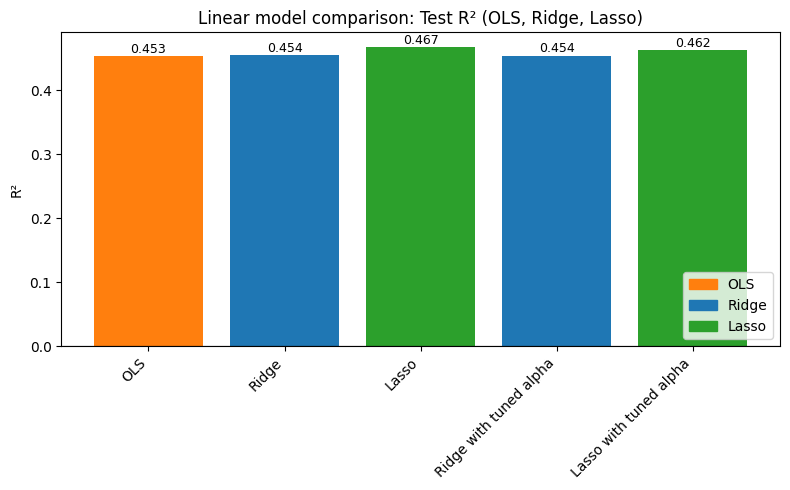

In [156]:
family_colors = {'OLS': 'tab:orange', 'Ridge': 'tab:blue', 'Lasso': 'tab:green'}
bar_colors = [family_colors[name.split()[0]] for name in results_df_linear.index]

plt.figure(figsize=(8, 5))
bars = plt.bar(results_df_linear.index, results_df_linear['R2'], color=bar_colors)
for b, v in zip(bars, results_df_linear['R2']):
    plt.text(b.get_x() + b.get_width() / 2, v + 0.005, f'{v:.3f}', ha='center', fontsize=9)
plt.axhline(0, color='k', lw=0.8)
plt.ylabel('R²')
plt.title('Linear model comparison: Test R² (OLS, Ridge, Lasso)')
plt.xticks(rotation=45, ha='right')
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in family_colors.values()]
plt.legend(handles, family_colors.keys(), loc='lower right')
plt.tight_layout()
plt.savefig('../charts/linear_models_r2.png')
plt.show()

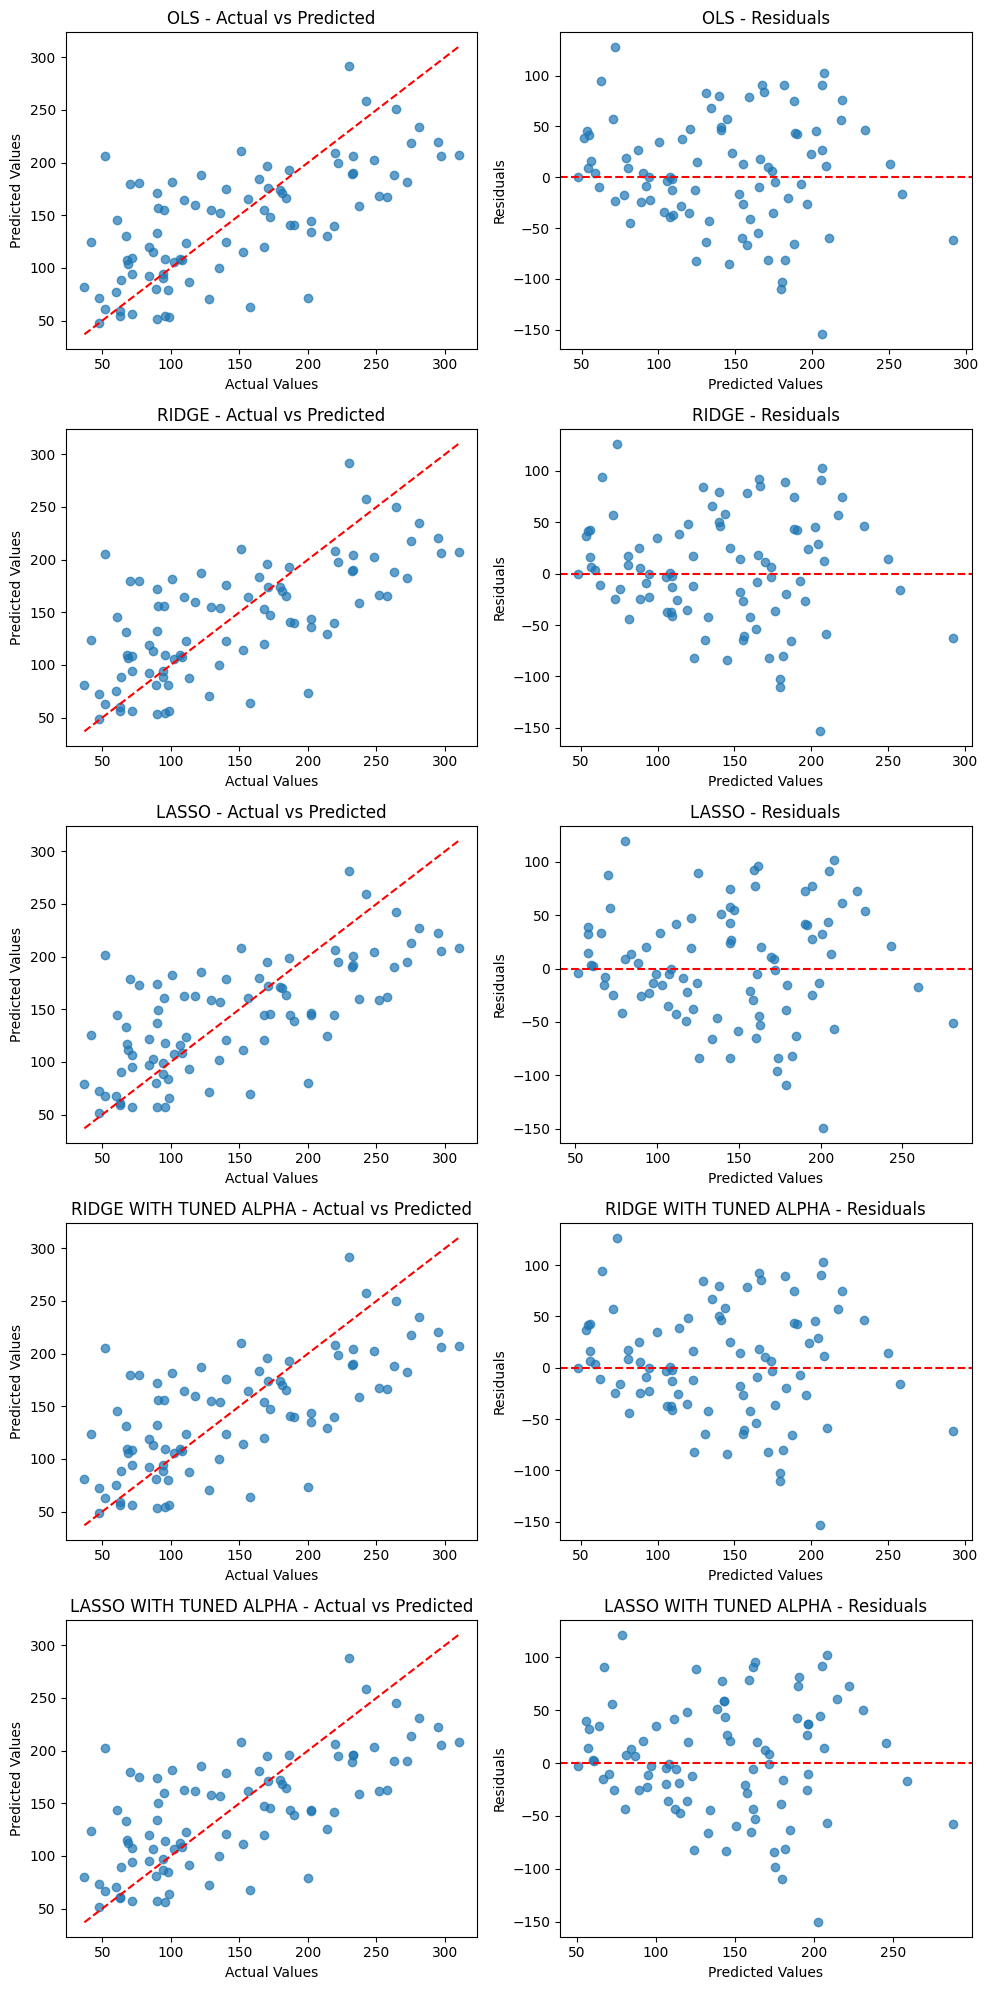

In [157]:
# Plot predictions vs actual values, and residuals, for each model as subplots
fig, axes = plt.subplots(len(models), 2, figsize=(10, 4 * len(models)))

for (model_name, model), (ax_pred, ax_resid) in zip(models.items(), axes):
    pipe = Pipeline([
        ('scaler', StandardScaler()),
        ('model', model)
    ])
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    residuals = y_test - y_pred

    ax_pred.scatter(y_test, y_pred, alpha=0.7)
    ax_pred.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
    ax_pred.set_xlabel("Actual Values")
    ax_pred.set_ylabel("Predicted Values")
    ax_pred.set_title(f"{model_name.upper()} - Actual vs Predicted")

    ax_resid.scatter(y_pred, residuals, alpha=0.7)
    ax_resid.axhline(0, color='r', linestyle='--')
    ax_resid.set_xlabel("Predicted Values")
    ax_resid.set_ylabel("Residuals")
    ax_resid.set_title(f"{model_name.upper()} - Residuals")

plt.tight_layout()
plt.show()


Text(0, 0.5, 'standardized coef')

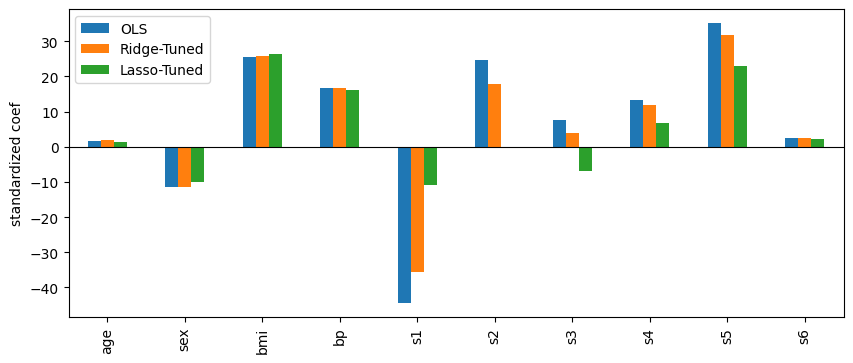

In [158]:
fitted_tuned = {
    'OLS': Pipeline([('s', StandardScaler()), ('m', LinearRegression())]).fit(X_train, y_train),
    'Ridge-Tuned': ridge_grid.best_estimator_, 'Lasso-Tuned': lasso_grid.best_estimator_}
coef_df_tuned = pd.DataFrame({k: v[-1].coef_ for k, v in fitted_tuned.items()}, index=X.columns)
coef_df_tuned.plot.bar(figsize=(10, 4))
plt.axhline(0, color='k', lw=0.8)
plt.ylabel('standardized coef')

# 3b. Introduce Polynomial features and Evaluate the model

Having established linear OLS/Ridge/Lasso as baselines (test R² ≈ 0.45–0.47), we now explore whether richer feature representations can better capture non-linear relationships and interactions between predictors. This section introduces polynomial feature engineering to extend the linear models.

**Steps performed:**
1. Built a reusable `make_poly_pipeline` combining: scaling → `PolynomialFeatures` → re-scaling → model, ensuring polynomial terms are generated and scaled consistently.
2. Used `tune_reg_model_with_polynomial` to grid-search the best `alpha` for Ridge and Lasso at each polynomial degree via `GridSearchCV` with 5-fold CV.
3. Evaluated OLS, Ridge, and Lasso at degrees 1, 2, and 3, capturing train R², CV R², test R², number of features, and number of non-zero coefficients.
4. For degree 2, additionally evaluated interaction-only models (pairwise interactions without squared terms) to isolate the effect of interactions from pure polynomial curvature.
5. Compared train vs. test R² across all model/degree combinations to diagnose overfitting (e.g., OLS degree 3 severely overfits, with negative test R²).
6. Visualized results with grouped bar charts (training vs. test R²) to highlight how regularization (Ridge/Lasso) controls variance as polynomial degree increases, while plain OLS degrades sharply at higher degrees.

In [159]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.model_selection import cross_validate

# Function to create a polynomial regression pipeline with optional interaction terms
def make_poly_pipeline(model, degree=2,interaction_only=False):
    return Pipeline([
        ('scaler1', StandardScaler()),
        ('poly', PolynomialFeatures(degree=degree,interaction_only=interaction_only, include_bias=False)),
        ('scaler2', StandardScaler()), # adding the second scaler after polynomial features
        ('model', model)
    ])

# perform polynomial grid search for Ridge and Lasso models
def tune_reg_model_with_polynomial(model, degree, alphas,interaction_only=False):
    pipe = make_poly_pipeline(model, degree, interaction_only=interaction_only)
    return GridSearchCV(pipe, {'model__alpha': alphas},
                        cv=KFold(5, shuffle=True, random_state=42), scoring='r2').fit(X_train, y_train)

rcv = KFold(n_splits=5, shuffle=True, random_state=42)
rows = []
for degree in [1, 2, 3]:
    ests = {
        'OLS':   make_poly_pipeline(LinearRegression(), degree),
        'Ridge': tune_reg_model_with_polynomial(Ridge(), degree, np.logspace(-1, 4, 40)).best_estimator_,
        'Lasso': tune_reg_model_with_polynomial(Lasso(max_iter=100000, selection='random', random_state=42),
                            degree, np.logspace(-1, 1.5, 30)).best_estimator_,
    }
    if degree == 2: # Add Interaction Terms for degree 2 only
        ests['OLS with_interaction']   = make_poly_pipeline(LinearRegression(), degree, interaction_only=True)
        ests['Ridge with_interaction'] = tune_reg_model_with_polynomial(Ridge(), degree, np.logspace(-1, 4, 40),
                                                                         interaction_only=True).best_estimator_
        ests['Lasso with_interaction'] = tune_reg_model_with_polynomial(
            Lasso(max_iter=100000, selection='random', random_state=42),
            degree, np.logspace(-1, 1.5, 30), interaction_only=True).best_estimator_
        
    for name, est in ests.items():
        # Score on both R² and RMSE so the R²-based ranking can be cross-checked against actual error magnitude
        cv = cross_validate(est, X_train, y_train, cv=rcv,
                            scoring=['r2', 'neg_root_mean_squared_error'],
                            return_train_score=True, n_jobs=-1)
        est.fit(X_train, y_train)
        y_pred_test = est.predict(X_test)
        coef = est.named_steps['model'].coef_
        rows.append(dict(degree=degree, 
                         model=name,
                         train_r2=cv['train_r2'].mean(),
                         cv_r2=cv['test_r2'].mean(), 
                         test_r2=r2_score(y_test, y_pred_test),
                         cv_rmse=-cv['test_neg_root_mean_squared_error'].mean(),
                         test_rmse=root_mean_squared_error(y_test, y_pred_test),
                         n_features=len(coef),
                         n_nonzero=int((coef != 0).sum())))
results_df = pd.DataFrame(rows)
print(results_df.round(3))

    degree                   model  train_r2     cv_r2  test_r2   cv_rmse  \
0        1                     OLS     0.531     0.480    0.453    55.395   
1        1                   Ridge     0.531     0.481    0.454    55.374   
2        1                   Lasso     0.530     0.481    0.456    55.349   
3        2                     OLS     0.626     0.339    0.416    62.505   
4        2                   Ridge     0.569     0.451    0.502    56.850   
5        2                   Lasso     0.532     0.470    0.510    55.941   
6        2    OLS with_interaction     0.611     0.360    0.478    61.518   
7        2  Ridge with_interaction     0.570     0.461    0.510    56.368   
8        2  Lasso with_interaction     0.539     0.472    0.514    55.841   
9        3                     OLS     0.980 -1279.029  -14.561  2216.918   
10       3                   Ridge     0.570     0.407    0.419    59.261   
11       3                   Lasso     0.524     0.446    0.484    57.233   

In [160]:
# Rank by CV R² (primary metric) and cross-check with CV/test RMSE and model simplicity (n_nonzero),
# since the top few test R² scores are within noise of each other on a ~89-row test set.
ranked = results_df.sort_values('cv_r2', ascending=False)
print(ranked[['degree', 'model', 'cv_r2', 'test_r2', 'cv_rmse', 'test_rmse', 'n_nonzero']].head(10).to_string(index=False))

 degree                  model    cv_r2  test_r2   cv_rmse  test_rmse  n_nonzero
      1                  Lasso 0.481299 0.456011 55.348882  53.685553          9
      1                  Ridge 0.480782 0.453908 55.374127  53.789192         10
      1                    OLS 0.480365 0.452603 55.394633  53.853446         10
      2 Lasso with_interaction 0.471764 0.514079 55.840948  50.739379         16
      2                  Lasso 0.469890 0.510266 55.940677  50.938066         14
      2 Ridge with_interaction 0.461497 0.509825 56.368343  50.960969         55
      2                  Ridge 0.451191 0.502478 56.849774  51.341484         65
      3                  Lasso 0.446057 0.484210 57.233328  52.275541         16
      3                  Ridge 0.406956 0.419171 59.261152  55.473599        285
      2   OLS with_interaction 0.359684 0.477954 61.517789  52.591607         55


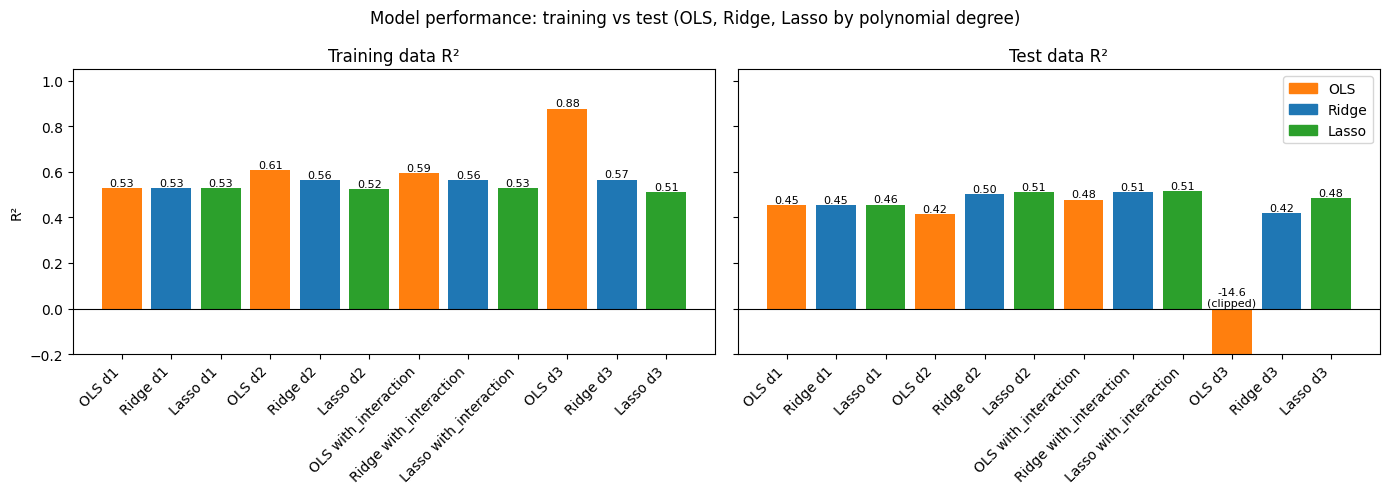

In [161]:
# 1. Fit all models (OLS / Ridge / Lasso at degrees 1-3, degree 2 with interaction) and keep the best fitted estimators
fitted = {}
for degree in [1, 2, 3]:
    fitted[f'OLS d{degree}']   = make_poly_pipeline(LinearRegression(), degree).fit(X_train, y_train)
    fitted[f'Ridge d{degree}'] = tune_reg_model_with_polynomial(Ridge(), degree, np.logspace(-1, 4, 40)).best_estimator_
    fitted[f'Lasso d{degree}'] = tune_reg_model_with_polynomial(Lasso(max_iter=100000, selection='random', random_state=42),
                                            degree, np.logspace(-1, 1.5, 30)).best_estimator_
    if degree == 2:
        fitted[f'OLS with_interaction']   = make_poly_pipeline(LinearRegression(), degree, interaction_only=True).fit(X_train, y_train)
        fitted[f'Ridge with_interaction'] = tune_reg_model_with_polynomial(Ridge(), degree, np.logspace(-1, 4, 40),
                                                                         interaction_only=True).best_estimator_
        fitted[f'Lasso with_interaction'] = tune_reg_model_with_polynomial(
            Lasso(max_iter=100000, selection='random', random_state=42),
            degree, np.logspace(-1, 1.5, 30), interaction_only=True).best_estimator_

# 2. Train and test R² for each
scores = pd.DataFrame({
    name: {'train': r2_score(y_train, est.predict(X_train)),
           'test':  r2_score(y_test,  est.predict(X_test))}
    for name, est in fitted.items()}).T

# 3. Plot: training vs testing, same y-axis
YMIN = -0.2      # OLS degree 3 on test is far below this, so clip it
family_colors = {'OLS': 'tab:orange', 'Ridge': 'tab:blue', 'Lasso': 'tab:green'}
bar_colors = [family_colors[n.split()[0]] for n in scores.index]

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, split, title in zip(axes, ['train', 'test'], ['Training data R²', 'Test data R²']):
    vals = scores[split]
    bars = ax.bar(scores.index, vals.clip(lower=YMIN), color=bar_colors)
    for b, v in zip(bars, vals):
        label = f'{v:.2f}' if v >= YMIN else f'{v:.1f}\n(clipped)'
        ax.text(b.get_x() + b.get_width() / 2, max(v, 0) + 0.01, label, ha='center', fontsize=8)
    ax.axhline(0, color='k', lw=0.8)
    ax.set_ylim(YMIN, 1.05)
    ax.set_title(title)
    plt.setp(ax.get_xticklabels(), rotation=45, ha='right')
axes[0].set_ylabel('R²')
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in family_colors.values()]
axes[1].legend(handles, family_colors.keys(), loc='upper right')
plt.suptitle('Model performance: training vs test (OLS, Ridge, Lasso by polynomial degree)')
plt.tight_layout()
plt.savefig('../charts/train_vs_test_r2.png')
plt.show()

#### Model performance: training vs test (OLS, Ridge, Lasso by polynomial degree)

**Degree 1 (linear baseline):** OLS, Ridge, and Lasso all land around train R² ≈ 0.53 and test R² ≈ 0.45–0.46. Train and test scores are close, so there's no meaningful overfitting at this degree — consistent with the earlier linear-model results.

**Degree 2 (squared + interaction terms):** Unregularized OLS's train R² rises to 0.61, but test R² actually *drops* to 0.42 — the extra squared terms let OLS fit training noise rather than genuine signal. Ridge d2 (train 0.56, test 0.50) and Lasso d2 (train 0.52, test 0.51) show the opposite pattern: regularization suppresses that extra variance and produces the best test scores on the whole chart.

**Degree 2, interaction-only:** OLS with_interaction mirrors the full degree-2 OLS (train 0.59, test 0.48) — still overfitting without regularization. Ridge/Lasso with_interaction both reach test R² ≈ 0.51, matching the full degree-2 regularized models. This suggests most of the degree-2 gain comes from pairwise interactions, while the squared terms add little once regularized.

**Degree 3 (cubic):** Unregularized OLS severely overfits — train R² jumps to 0.88 while test R² collapses to roughly -14.6 (clipped on the chart), a textbook bias-variance failure from an overly flexible model with too few data points (442 rows) relative to the expanded feature space. Ridge d3 reins this in (train 0.57, test 0.42) but still trails the degree-2 Ridge model. Lasso d3 does best among degree-3 variants (train 0.51, test 0.48), likely because its L1 penalty zeroes out many higher-order terms — effectively acting as automatic feature selection — though it still doesn't beat the degree-2 results.

**Key takeaways:**
- The train/test gap widens sharply with polynomial degree for unregularized OLS, while Ridge and Lasso keep that gap narrow at every degree — regularization is essential once polynomial/interaction terms are introduced.
- Degree 2 (regularized, with or without pure interaction terms) is the sweet spot, improving test R² by ~0.05 over the degree-1 baseline.
- Degree 3 provides no benefit and is actively harmful without strong regularization, so it isn't worth pursuing further for this dataset.
- Lasso consistently matches or slightly edges out Ridge, likely because pruning irrelevant polynomial terms reduces the multicollinearity introduced by the expanded feature space.


# Summary

**EDA Insights:** The diabetes dataset showed a right-skewed target variable with `bmi`, `bp`, `s4`, and `s5` exhibiting the strongest linear relationships with `target`. Notable multicollinearity was identified upfront — `s1`/`s2` (corr ≈ 0.90) and `s3`/`s4` (corr ≈ -0.74) — flagging a risk for unregularized linear models.

**Model Performance Ranking (by CV R², cross-checked with RMSE and model simplicity):**

Ranking by mean 5-fold CV R² (rather than the single-split test R²) tells a different story than it first appeared. The degree-2 interaction models posted the best **test** R² (0.510–0.514), but under CV the plain **degree-1** linear models come out on top:
1. **Lasso (degree 1)** — highest CV R² (0.481) and lowest CV RMSE (55.35) of every model tried, while using only 9 of 10 features — the best balance of accuracy, stability, and simplicity.
2. **Ridge (degree 1)** — CV R² (0.481) and CV RMSE (55.37) essentially tied with Lasso.
3. **OLS (degree 1)** — CV R² (0.480) and CV RMSE (55.39), indistinguishable from Ridge/Lasso at degree 1.

All three degree-1 models beat every degree-2 and degree-3 variant on CV R² and CV RMSE — including Lasso with_interaction (degree 2), which had the best *test* R² (0.514) but a lower CV R² (0.472) and higher CV RMSE (55.84) than the degree-1 models. This is a direct illustration of why test R² alone shouldn't decide a winner: the single ~89-row test split happened to favor the extra polynomial/interaction terms, but 5-fold CV shows they don't generalize as consistently.

**Why the polynomial models look better on test R² but worse on CV R²:** 
- The train→CV gap widens as model complexity increases.
- For Lasso — degree-1 Lasso drops from train R² 0.530 to CV R² 0.481 (a gap of 0.049), 
- Degree-2 Lasso drops from 0.532 to 0.470 (gap 0.062), 
- Degree-2 Lasso with_interaction drops from 0.539 to 0.472 (gap 0.067)
- Degree-3 Lasso drops from 0.524 to 0.446 (gap 0.078). 

The gap grows further without regularization: OLS degree 2 collapses from train R² 0.626 to CV R² 0.339, and OLS degree 3 catastrophically overfits (train R² 0.980, CV R² ≈ -1279) — a severe multicollinearity-driven failure once the feature space increases to 285 columns.

**Collinearity and Regularization:** 
- The dataset's inherent multicollinearity (`s1`/`s2`/`s3`/`s4` block) becomes far more pronounced once polynomial and interaction terms are introduced, expanding the feature space from 10 to 65–285 correlated columns. 
- Ridge and Lasso both keep OLS's instability in check — Ridge by shrinking all correlated coefficients proportionally, Lasso by zeroing out many of them entirely (e.g., Lasso with_interaction keeps only 16 of 55 features non-zero) 

**Why degree-1 wins:** 
- With only 442 rows (353 for training), the dataset can't reliably support 55–285 polynomial features, even when Lasso's L1 penalty picks out a sparse subset. 
- The original 10 features already capture most of the real linear signal (consistent with the EDA correlations), so polynomial expansion mainly adds noise rather than genuinely better in prediction. 
- At degree 1, Lasso's slight edge over Ridge/OLS comes from dropping one weakly informative feature, trimming noise without losing real signal.

**Overall takeaway:** 
- The simplest model — Lasso (or equivalently Ridge/OLS) at degree 1 — is the most robust choice for this dataset based on cross-validated R² and RMSE, despite degree-2 polynomial models appearing to win on a single test split. This tells the model selection should rely on cross-validated metrics (ideally cross-checked with RMSE and model simplicity) rather than a single test R² score for test data set with lesser records.